In [1]:
import matplotlib.pyplot as plt
import numpy as np

from mpl_toolkits.basemap import Basemap

import xarray as xr
import pandas as pd
import cmocean

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.colors as colors

from mpl_toolkits.axes_grid1 import AxesGrid
from mpl_toolkits.basemap import Basemap
from scipy.optimize import curve_fit
from datetime import datetime

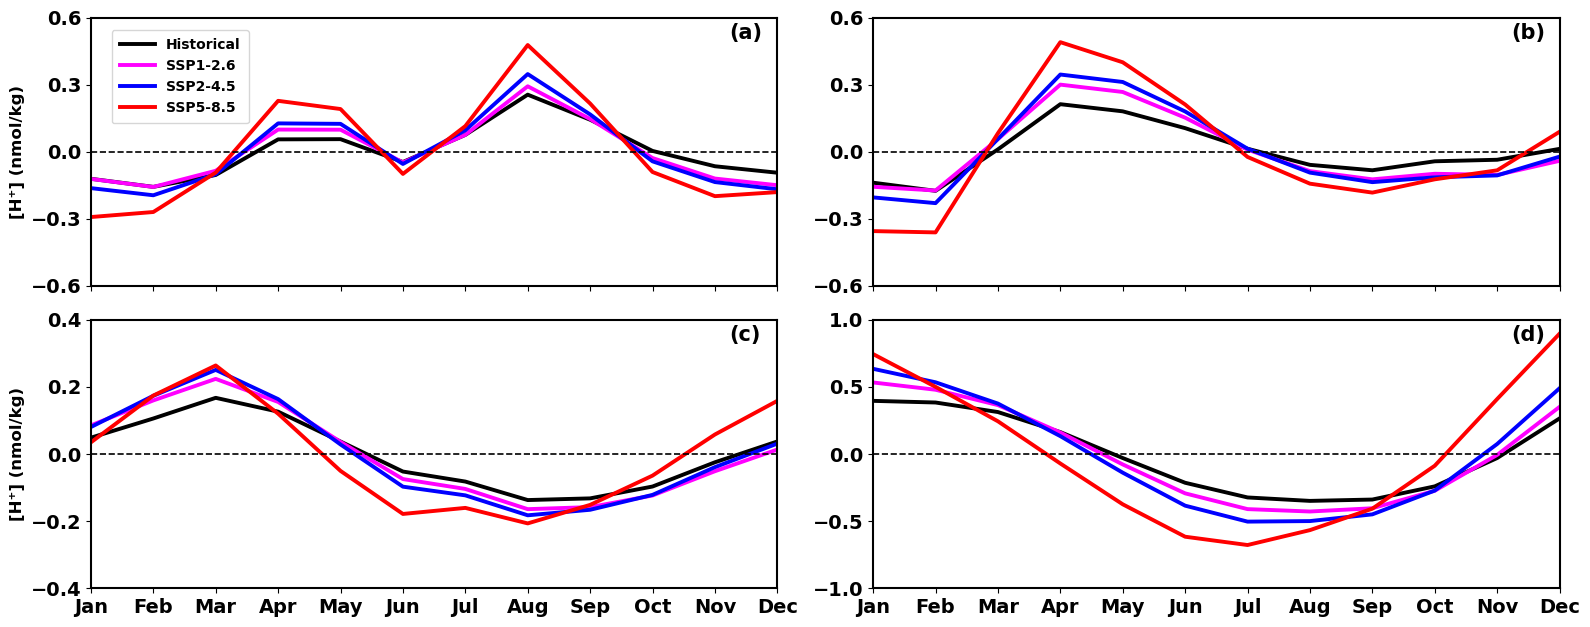

In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

base = "seasonal_bc"

regions = ['as', 'bob', 'cio', 'sio']
region_labels = ['AS', 'BoB', 'CIO', 'SIO']

def load_var(path, var_name=None):
    try:
        ds = xr.open_dataset(path, engine='netcdf4')
        if var_name is None:
            var_name = list(ds.data_vars)[0]
        return ds.squeeze()[var_name]
    except Exception as e:
        print(f"Error loading {path}: {e}")
        return None


h_data = {}

for r in regions:
    h_data[r] = {}

    h_data[r]['hist']   = load_var(f"{base}/{r}_hist_seasonal_H+.nc") * 1e9
    h_data[r]['ssp126'] = load_var(f"{base}/{r}_FF_seasonal_H+_ssp126.nc") * 1e9
    h_data[r]['ssp245'] = load_var(f"{base}/{r}_FF_seasonal_H+_ssp245.nc") * 1e9
    h_data[r]['ssp585'] = load_var(f"{base}/{r}_FF_seasonal_H+_ssp585.nc") * 1e9


months = np.arange(12)

xtick_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

yticks_H = [
    np.arange(-0.6, 0.7, 0.3),
    np.arange(-0.6, 0.7, 0.3),
    np.arange(-0.4, 0.5, 0.2),
    np.arange(-1.0, 1.1, 0.5)
]

ylims_H = [
    (-0.6, 0.6),
    (-0.6, 0.6),
    (-0.4, 0.4),
    (-1.0, 1.0)
]

colors = {
    'hist': 'black',
    'ssp126': 'magenta',
    'ssp245': 'blue',
    'ssp585': 'red'
}

labels = {
    'hist': 'Historical',
    'ssp126': 'SSP1-2.6',
    'ssp245': 'SSP2-4.5',
    'ssp585': 'SSP5-8.5'
}

fig, axes = plt.subplots(2, 2, figsize=(16, 7), sharex=True)
axes = axes.flatten()

subplot_labels = ['(a)', '(b)', '(c)', '(d)']

for i, ax in enumerate(axes):
    r = regions[i]

    # Plot all scenarios
    for scen in ['hist', 'ssp126', 'ssp245', 'ssp585']:
        data = h_data[r][scen]
        if data is not None:
            ax.plot(months, data,
                    color=colors[scen],
                    linewidth=2.8,
                    label=labels[scen])

    
    ax.axhline(0, linestyle='--', linewidth=1.2, color='black')

    # Axis styling
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

    if i in [0, 2]:
        ax.set_ylabel('[H⁺] (nmol/kg)', fontsize=12, fontweight='bold')

    # Y-axis settings
    ax.set_ylim(ylims_H[i])
    ax.set_yticks(yticks_H[i])

    ax.set_xticks(months)
    ax.set_xticklabels(xtick_labels, fontsize=14, fontweight='bold')
    ax.set_xlim(0, 11)

    ax.tick_params(axis='both', labelsize=14)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')

    # Subplot labels
    ax.text(0.93, 0.98, subplot_labels[i],
            transform=ax.transAxes,
            fontsize=15, fontweight='bold',
            va='top', ha='left')

    # Legend only in first subplot
    if i == 0:
        ax.legend(
            loc='upper left',
            bbox_to_anchor=(0.02, 0.98),
            fontsize=18,
            frameon=True,
            prop={'weight': 'bold'},
            borderpad=0.6,
            handlelength=2.5
        )

plt.tight_layout(rect=[0, 0.05, 1, 0.96])

# plt.savefig("seasonal_cycles_Hplus_IO_SSPs_review_f2.png",
#             dpi=300, bbox_inches='tight')

plt.show()